In [1]:
# When this notebook was last run (in Pacific Time)
from datetime import datetime

from dateutil import tz

now = datetime.now(tz.gettz('America/Los_Angeles'))
print(f'Last run: {now:%Y-%m-%d %H:%M:%S %Z}')

Last run: 2026-10-28 22:27:02 PDT


This notebook demonstrates the pipeline for using the equivalent linear method to perform site response analysis.

In [2]:
from PySeismoSoil.class_damping_calibration import Damping_Calibration
from PySeismoSoil.class_ground_motion import Ground_Motion
from PySeismoSoil.class_hh_calibration import HH_Calibration
from PySeismoSoil.class_simulation import Nonlinear_Simulation
from PySeismoSoil.class_Vs_profile import Vs_Profile

To perform a nonlinear linear analysis, we need the following information:

- Input acceleration
- $V_S$ profile
- HH model parameters for describing $G/G_{\max}$ and damping behaviors (of every soil layer)

In [3]:
input_accel = Ground_Motion('../tests/files/sample_accel.txt', unit='cm/s/s')
vs_profile = Vs_Profile('../tests/files/profile_FKSH14.txt')

(`Vs_Profile` class: [documentation](https://pyseismosoil.readthedocs.io/en/stable/api_docs/class_Vs_profile.html) and [examples](./Demo_02_Vs_Profile.ipynb). `Ground_Motion` class: [documentations](https://pyseismosoil.readthedocs.io/en/stable/api_docs/class_ground_motion.html) and [examples](./Demo_01_Ground_Motion.ipynb).)


----------+----------+-------------+------------------+--------------
  Thk [m] | Vs [m/s] | Damping [%] | Density [kg/m^3] | Material No. 
----------+----------+-------------+------------------+--------------
   2.00   |  120.0   |    2.000    |      1466.0      |      1       
   6.00   |  190.0   |    2.000    |      1900.0      |      2       
  44.00   |  280.0   |    2.000    |      1900.0      |      3       
  54.00   |  1030.0  |    2.000    |      2125.0      |      4       
   9.00   |  1210.0  |    1.000    |      2243.0      |      5       
   0.00   |  1210.0  |    1.000    |      2243.0      |      0       
----------+----------+-------------+------------------+--------------

(Vs30 = 236.6 m/s)



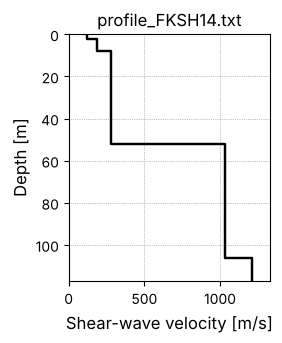

In [4]:
vs_profile.summary()

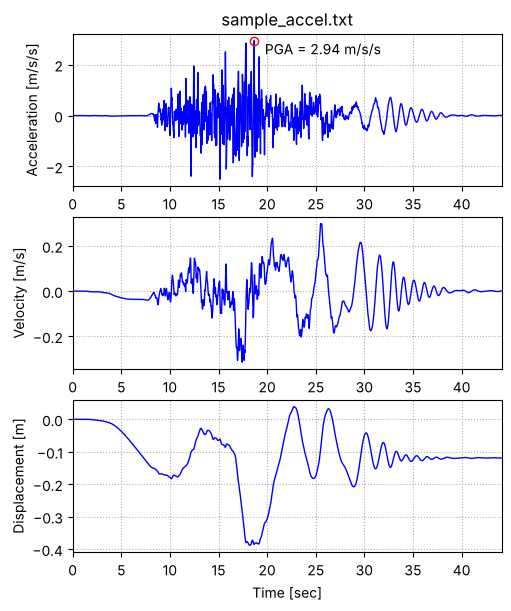

In [5]:
input_accel.plot();

The users often only know the $V_S$ profile and the input motion. In this case, we can empirically estimate HH parameters for $G/G_{\max}$ ("HH_G parameters") and HH parameters for damping curves ("HH_x parameters") from the $V_S$ profile:

Estimate HH_G parameters from the $V_S$ profile, using the "HH calibration" procedure proposed by [Shi and Asimaki (2017)](http://resolver.caltech.edu/CaltechAUTHORS:20170404-150827374) via the [`HH_Calibration` class](./Pipeline_02_HH_Calibration.ipynb):

In [6]:
hh_c = HH_Calibration(vs_profile)
hh_g_param = hh_c.fit()

========== Start optimizing for HH_G parameters ===========
------ G/Gmax not provided; will generate MKZ curves using Darendeli (2001): ------
-----------  FKZ optimization  -----------------------------
1/5: mu = 0.206, a = 100.0, gamma_t = 0.076%, d = 0.909
2/5: mu = 0.211, a = 100.0, gamma_t = 0.140%, d = 0.898
3/5: mu = 0.258, a = 100.0, gamma_t = 0.011%, d = 0.862
4/5: mu = 0.069, a = 100.0, gamma_t = 0.010%, d = 0.688
5/5: mu = 0.066, a = 100.0, gamma_t = 0.010%, d = 0.684


Estimate damping curves using empirical formulas proposed by [Darendeli (2001)](https://repositories.lib.utexas.edu/handle/2152/10396) via the [`Damping_Calibration` class](https://pyseismosoil.readthedocs.io/en/stable/api_docs/class_damping_calibration.html). And then, fit the HH model to the damping curves to obtain the HH_x parameters:

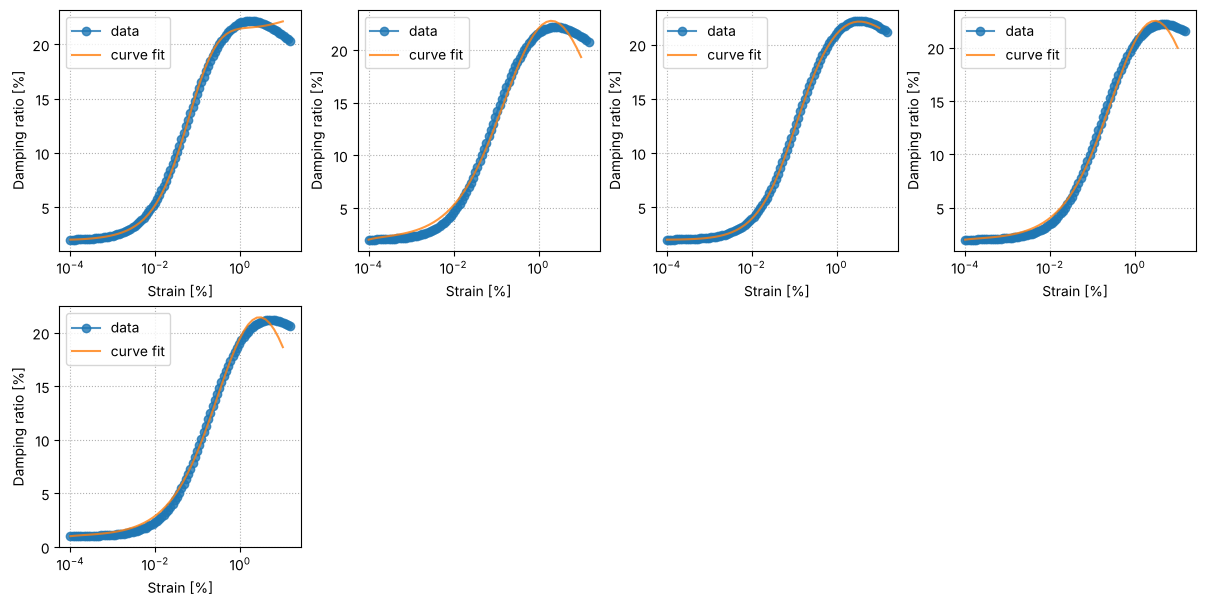

In [7]:
d_c = Damping_Calibration(vs_profile)
hh_x_param = d_c.get_HH_x_param(
    parallel=False,  # set `parallel` to `True` to use multiple CPU cores
    pop_size=200,
    n_gen=100,  # pop_size and n_gen control the speed and accuracy of the fit
    show_fig=True,
)

Initialize an `Nonlinear_Simulation` object. We use an "elastic" boundary condition in this example, which means that the input ground motion is the ground motion on a nearby reference rock site (or "rock outcrop site"). (If the input ground motion is the motion recorded in a borehole at the bottom of the $V_S$ profile, then use "rigid" as the boundary condition.)

In [8]:
nl_sim = Nonlinear_Simulation(
    vs_profile,
    input_accel,
    G_param=hh_g_param,
    xi_param=hh_x_param,
    boundary='elastic',
)

Then run the simulation with the `run()` method:

Nonlinear simulation running...
|---------------- Calculating --------------------|
|

|||

||

|||

|||

...

|||

||| 
 
Calculation finished. Writing results to disk...
 


Simulation finished. Now post processing.


Done.


`sim_dir` (./nonlinear_sim_2026-10-29_05-28-35) removed.


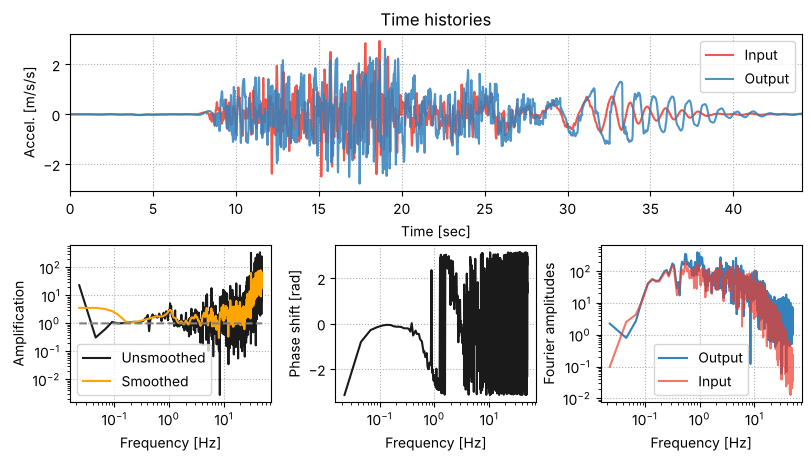

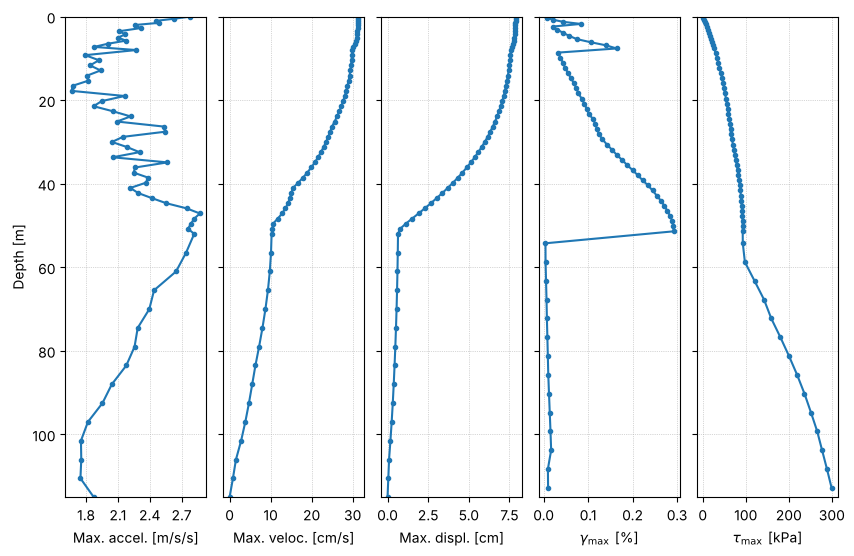

In [9]:
sim_results = nl_sim.run(
    show_fig=True,
    save_txt=False,
    # flip `save_txt` and `remove_sim_dir` to keep result as text files
    remove_sim_dir=True,
)

You can save the simulation results `sim_results` to the hard drive like this:

```python
>>> sim_results.to_txt()
```

To also save the figures (input/output ground motion, maximum accel/veloc/displ/strain/stress profiles), use the `plot()` method:

```python
>>> sim_results.plot(dpi=200, save_fig=True)
```

For more information about the `Simulation_Results` class, see its [documentation](https://pyseismosoil.readthedocs.io/en/stable/api_docs/class_simulation_results.html).